# Praktikum Data Mining – Evaluasi Model Klasifikasi
**Confusion Matrix, Accuracy, Precision, Recall dan F1-Score — Studi Kasus Deteksi Website Phishing**

Kelompok 7 Data Mining

Anggota: Lutfiah Sahira (24343039), Imam Atthahira (24343037), Rangga Dharma Putra (24343045). Mata kuliah: Data Mining · Dosen pengampu: Dr. Yeka Hendriyani, S.Kom., M.Kom. Program Studi Informatika, Departemen Teknik Elektronika, Fakultas Teknik, Universitas Negeri Padang

Dataset: Vrbančič, Fister, & Podgorelec (2020), *Datasets for phishing websites detection* (varian `dataset_small.csv`, letakkan di folder `data/`). Jalankan sel secara berurutan dari atas ke bawah.

## 4.1 – Menyiapkan dataset phishing

In [1]:
import numpy as np
import pandas as pd

# Sumber: Vrbancic dkk. (2020), varian dataset_small.csv (58.645 situs, 111 fitur URL)
raw = pd.read_csv('data/dataset_small.csv')
fitur = ['length_url', 'qty_dot_url', 'qty_hyphen_url', 'qty_slash_url', 'qty_equal_url',
         'qty_underline_url', 'qty_at_url', 'domain_length', 'directory_length', 'file_length']

# Skenario tidak seimbang: 200 situs phishing + 3.800 situs legitimate
phishing = raw[raw['phishing'] == 1].sample(200, random_state=42)
legit = raw[raw['phishing'] == 0].sample(3800, random_state=42)
df = pd.concat([phishing, legit])[fitur + ['phishing']]
df = df.rename(columns={'phishing': 'isPhishing'})
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
print('Dataset asli:', raw.shape, '| Dataset praktikum:', df.shape)
print(df.head())
print('Distribusi kelas:')
print(df['isPhishing'].value_counts())
print('Proporsi phishing:', round(df['isPhishing'].mean()*100, 2), '%')


Dataset asli: (58645, 112) | Dataset praktikum: (4000, 11)
   length_url  qty_dot_url  qty_hyphen_url  qty_slash_url  qty_equal_url  qty_underline_url  qty_at_url  domain_length  directory_length  file_length  isPhishing
0          18            1               0              0              0                  0           0             18                -1           -1           0
1          13            2               0              0              0                  0           0             13                -1           -1           0
2          16            2               0              0              0                  0           0             16                -1           -1           0
3          21            2               0              0              0                  0           0             21                -1           -1           0
4          17            2               0              0              0                  0           0             17             

## 4.1b – Visualisasi distribusi kelas

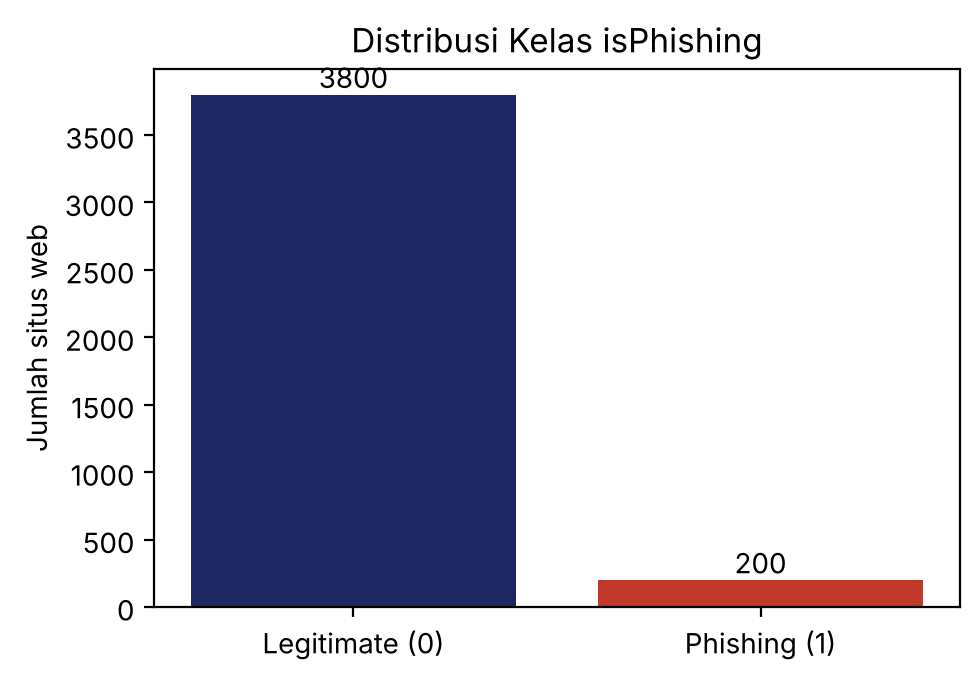

In [2]:
import matplotlib.pyplot as plt
counts = df['isPhishing'].value_counts().sort_index()
plt.figure(figsize=(5, 3.5))
bars = plt.bar(['Legitimate (0)', 'Phishing (1)'], counts.values, color=['#1E2761', '#C0392B'])
plt.bar_label(bars)
plt.ylabel('Jumlah situs web')
plt.title('Distribusi Kelas isPhishing')
plt.tight_layout()
plt.savefig('fig_distribusi_kelas.png', dpi=150)
plt.show()


## 4.2 – Membagi data dan melatih model

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
X = df.drop(columns='isPhishing')
y = df['isPhishing']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Data uji:', len(y_test))
print('Phishing pada data uji:', int(y_test.sum()), '| Phishing pada data latih:', int(y_train.sum()))


Data uji: 1200
Phishing pada data uji: 60 | Phishing pada data latih: 140


## 4.3 – Menghitung confusion matrix

In [4]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred, labels=[0,1])
tn, fp, fn, tp = cm.ravel()
print('Confusion matrix:\n', cm)
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')


Confusion matrix:
 [[952 188]
 [  8  52]]
TP=52, TN=952, FP=188, FN=8


## 4.4 – Perhitungan manual dan verifikasi scikit-learn

In [5]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
print(f'Accuracy={accuracy:.3f}; Precision={precision:.3f}; Recall={recall:.3f}; F1={f1:.3f}')
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print(accuracy_score(y_test,y_pred), precision_score(y_test,y_pred,zero_division=0),
      recall_score(y_test,y_pred,zero_division=0), f1_score(y_test,y_pred,zero_division=0))


Accuracy=0.837; Precision=0.217; Recall=0.867; F1=0.347
0.8366666666666667 0.21666666666666667 0.8666666666666667 0.3466666666666667


## 4.5 – Visualisasi confusion matrix

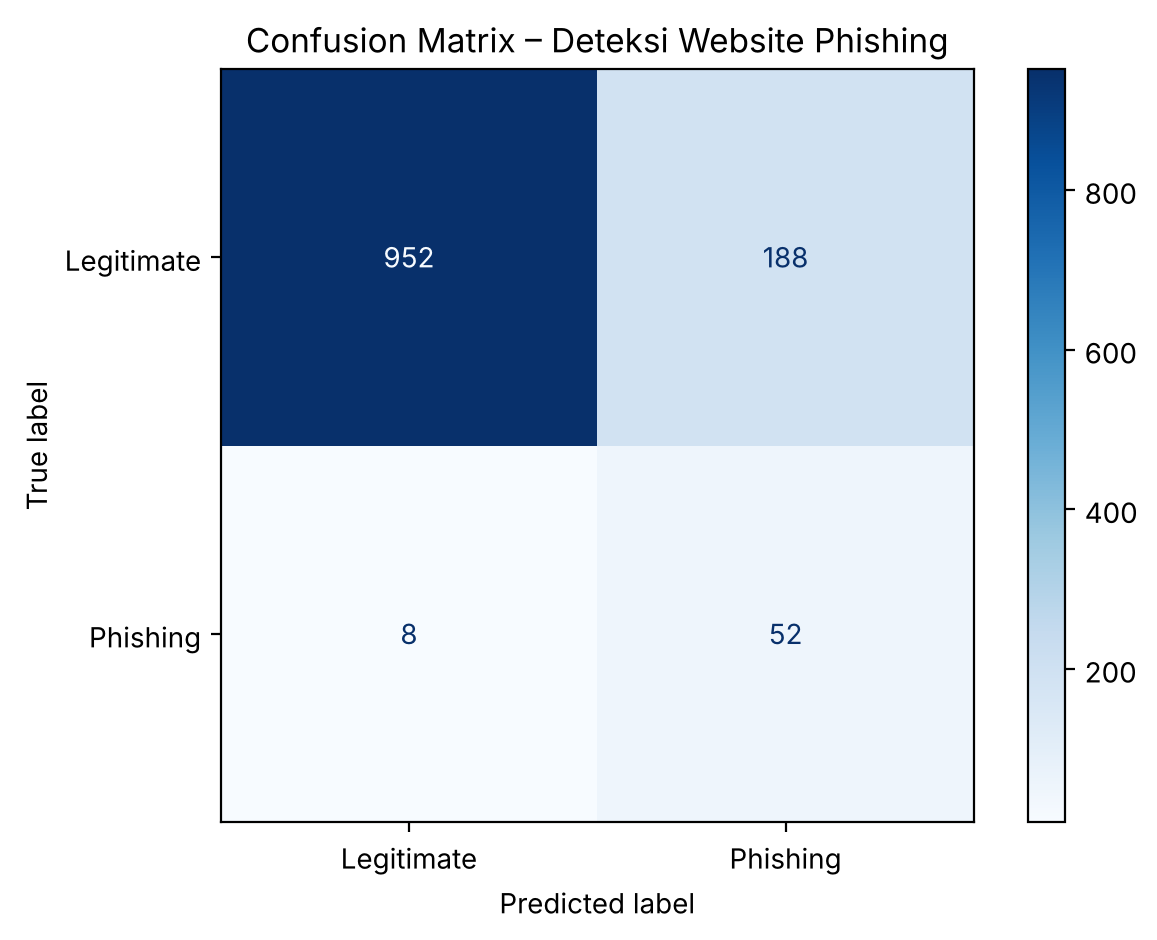

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['Legitimate','Phishing']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix – Deteksi Website Phishing')
plt.tight_layout()
plt.savefig('fig_cm_dt.png', dpi=150)
plt.show()


## 4.6 – Interpretasi kesalahan prediksi

In [7]:
print(f'FN = {fn}: situs phishing yang luput terdeteksi (pengguna berpotensi menjadi korban)')
print(f'FP = {fp}: situs legitimate yang salah ditandai phishing (situs sah terblokir)')
print(f'Phishing aktual pada data uji = {tp+fn}, berhasil ditemukan = {tp}')
print(f'Alarm phishing yang dibunyikan = {tp+fp}, alarm yang benar = {tp}')


FN = 8: situs phishing yang luput terdeteksi (pengguna berpotensi menjadi korban)
FP = 188: situs legitimate yang salah ditandai phishing (situs sah terblokir)
Phishing aktual pada data uji = 60, berhasil ditemukan = 52
Alarm phishing yang dibunyikan = 240, alarm yang benar = 52


## 4.7 – Eksperimen: baseline semua legitimate

In [8]:
baseline = np.zeros(len(y_test), dtype=int)
from sklearn.metrics import classification_report
print('Baseline accuracy:', accuracy_score(y_test, baseline))
print(classification_report(y_test, baseline, labels=[0,1], zero_division=0))
print('Decision Tree:')
print(classification_report(y_test, y_pred, labels=[0,1], zero_division=0))


Baseline accuracy: 0.95


              precision    recall  f1-score   support

           0       0.95      1.00      0.97      1140
           1       0.00      0.00      0.00        60

    accuracy                           0.95      1200
   macro avg       0.47      0.50      0.49      1200
weighted avg       0.90      0.95      0.93      1200

Decision Tree:
              precision    recall  f1-score   support

           0       0.99      0.84      0.91      1140
           1       0.22      0.87      0.35        60

    accuracy                           0.84      1200
   macro avg       0.60      0.85      0.63      1200
weighted avg       0.95      0.84      0.88      1200



## 4.8 – Eksperimen: pengaruh ambang prediksi

In [9]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)
    print(threshold, 'precision=', round(precision_score(y_test,pred,zero_division=0),3),
          'recall=', round(recall_score(y_test,pred,zero_division=0),3))


0.2 precision= 0.178 recall= 0.9
0.4 precision= 0.178 recall= 0.9
0.5 precision= 0.217 recall= 0.867
0.7 precision= 0.407 recall= 0.733


## T1 – Tugas 1 - hitung manual dan verifikasi

Confusion matrix (baris=aktual, kolom=prediksi):
 [[156  12]
 [  8  24]]
Accuracy  = (24+156)/200 = 0.9000
Precision = 24/(24+12) = 0.6667
Recall    = 24/(24+8) = 0.7500
F1-score  = 0.7059


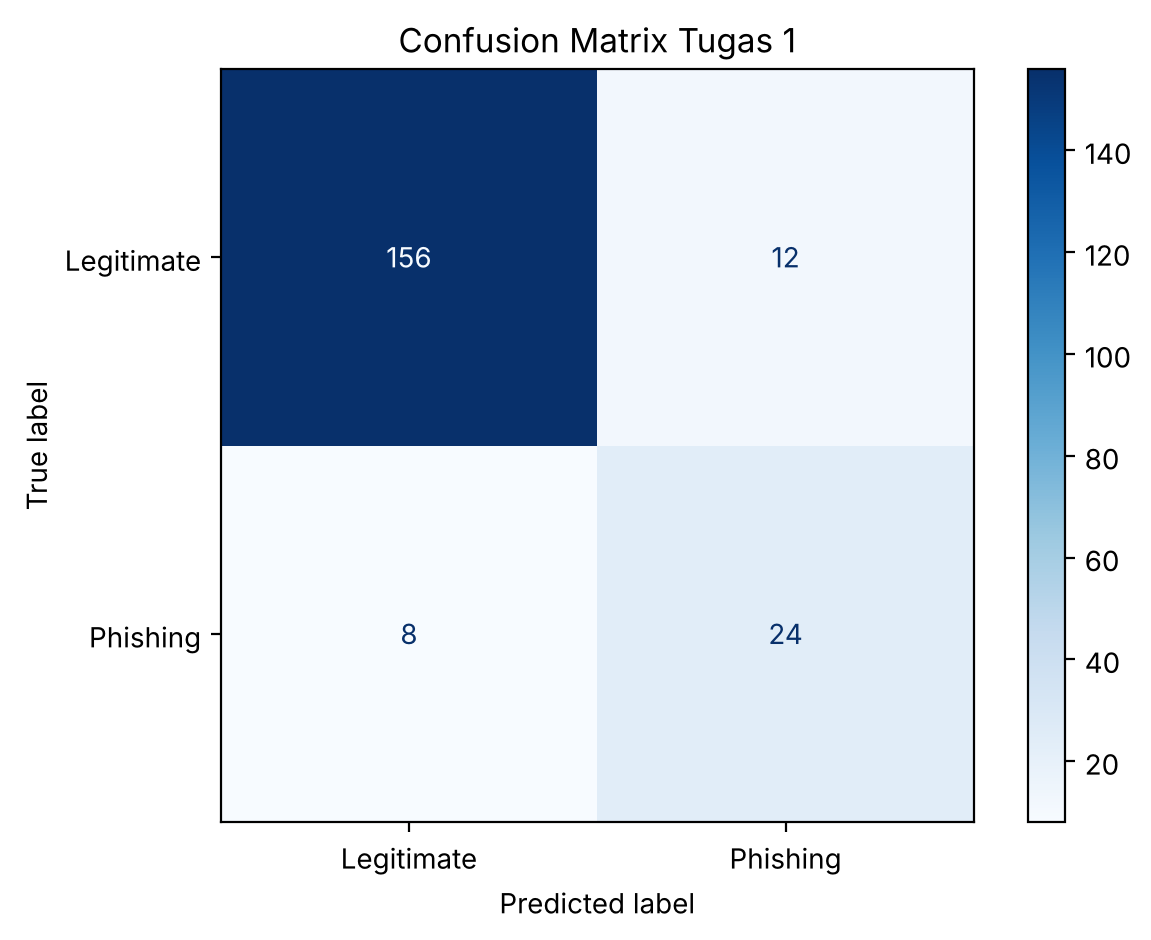

In [10]:
tp1, tn1, fp1, fn1 = 24, 156, 12, 8
cm1 = np.array([[tn1, fp1], [fn1, tp1]])
print('Confusion matrix (baris=aktual, kolom=prediksi):\n', cm1)
acc1 = (tp1 + tn1) / (tp1 + tn1 + fp1 + fn1)
pre1 = tp1 / (tp1 + fp1)
rec1 = tp1 / (tp1 + fn1)
f11 = 2 * pre1 * rec1 / (pre1 + rec1)
print(f'Accuracy  = ({tp1}+{tn1})/{tp1+tn1+fp1+fn1} = {acc1:.4f}')
print(f'Precision = {tp1}/({tp1}+{fp1}) = {pre1:.4f}')
print(f'Recall    = {tp1}/({tp1}+{fn1}) = {rec1:.4f}')
print(f'F1-score  = {f11:.4f}')
ConfusionMatrixDisplay(cm1, display_labels=['Legitimate','Phishing']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix Tugas 1'); plt.tight_layout()
plt.savefig('fig_task1_cm.png', dpi=150); plt.show()


## T3 – Tugas 3 - ringkasan baseline vs Decision Tree

                    Model  Accuracy  Precision  Recall    F1
Baseline semua legitimate     0.950      0.000   0.000 0.000
            Decision Tree     0.837      0.217   0.867 0.347


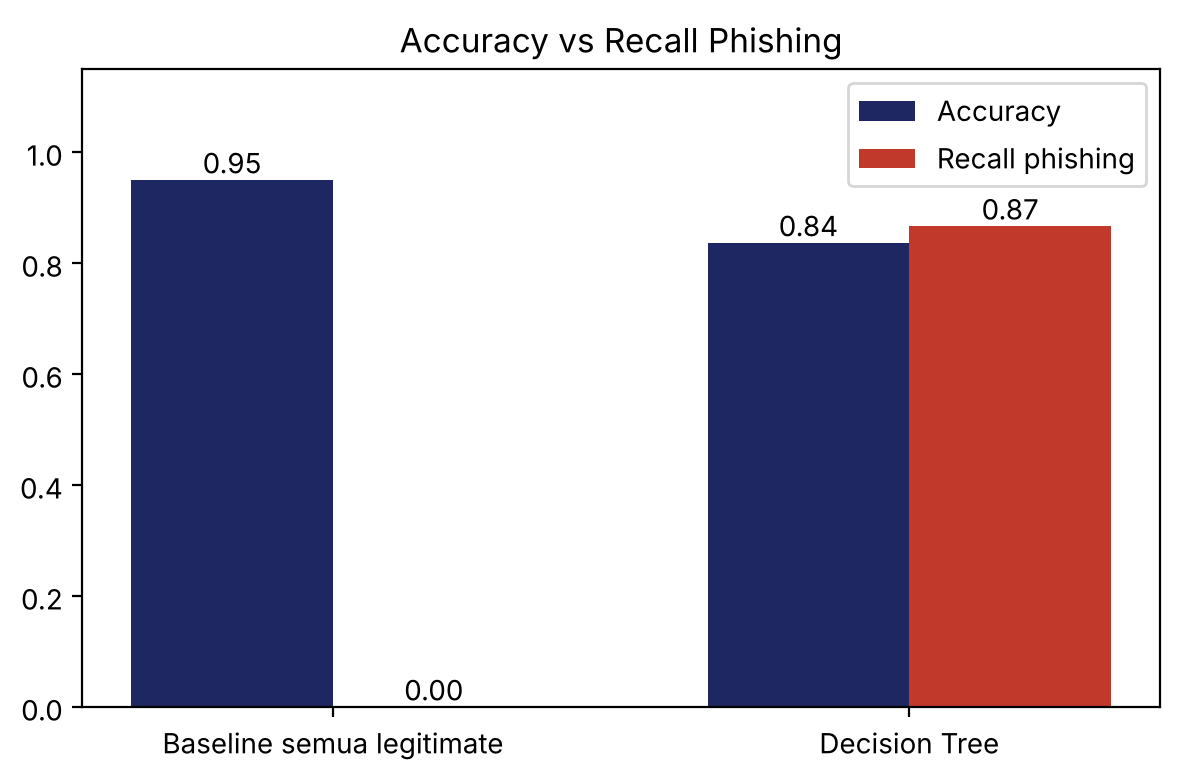

In [11]:
rows = []
for nama, p in [('Baseline semua legitimate', baseline), ('Decision Tree', y_pred)]:
    rows.append([nama, accuracy_score(y_test, p), precision_score(y_test, p, zero_division=0),
                 recall_score(y_test, p, zero_division=0), f1_score(y_test, p, zero_division=0)])
ringkas = pd.DataFrame(rows, columns=['Model','Accuracy','Precision','Recall','F1'])
print(ringkas.round(3).to_string(index=False))
plt.figure(figsize=(6, 4))
xs = np.arange(2); w = 0.35
b1 = plt.bar(xs - w/2, ringkas['Accuracy'], w, label='Accuracy', color='#1E2761')
b2 = plt.bar(xs + w/2, ringkas['Recall'], w, label='Recall phishing', color='#C0392B')
plt.bar_label(b1, fmt='%.2f'); plt.bar_label(b2, fmt='%.2f')
plt.xticks(xs, ringkas['Model']); plt.ylim(0, 1.15); plt.legend()
plt.title('Accuracy vs Recall Phishing'); plt.tight_layout()
plt.savefig('fig_baseline.png', dpi=150); plt.show()


## T4 – Tugas 4 - tabel threshold dan rekomendasi

 Threshold  TP  FP  FN  Precision  Recall    F1
       0.2  54 250   6      0.178   0.900 0.297
       0.4  54 250   6      0.178   0.900 0.297
       0.5  52 188   8      0.217   0.867 0.347
       0.7  44  64  16      0.407   0.733 0.524


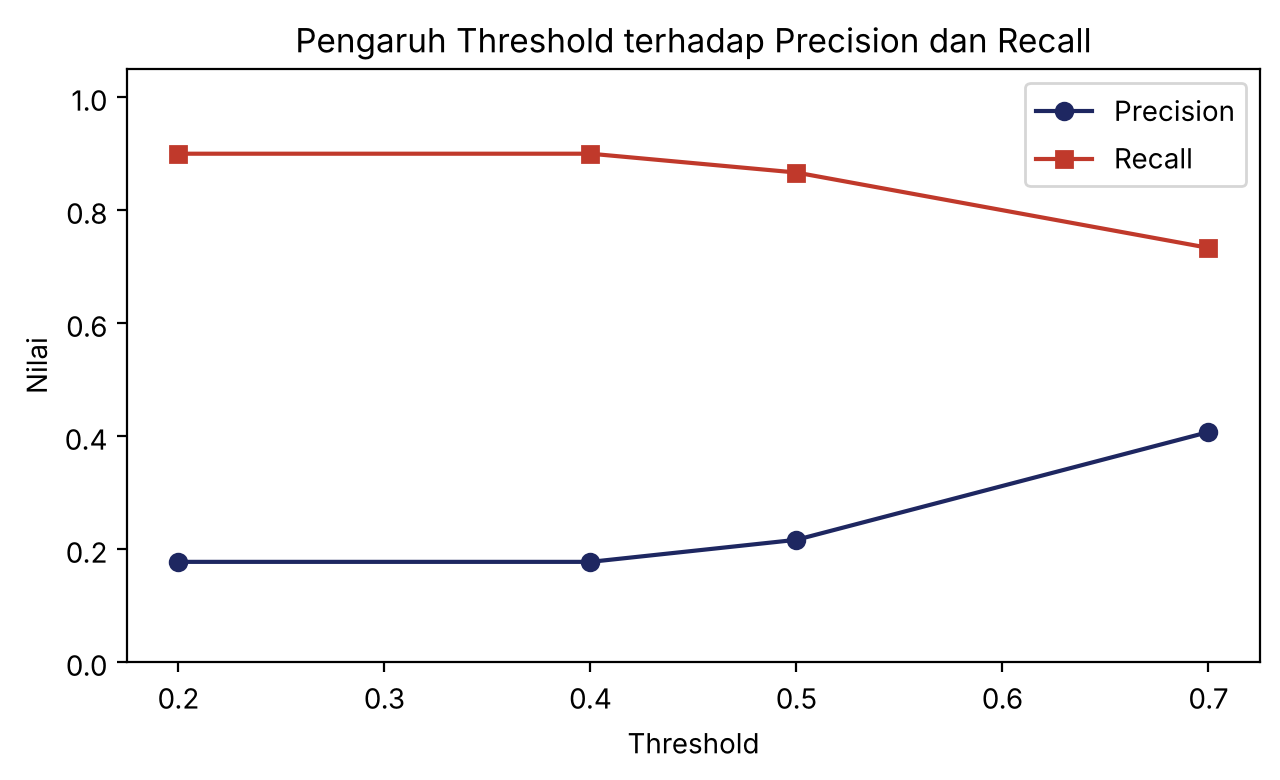

In [12]:
thr_list = [0.2, 0.4, 0.5, 0.7]
hasil = []
for th in thr_list:
    pr = (y_prob >= th).astype(int)
    t_n, f_p, f_n, t_p = confusion_matrix(y_test, pr, labels=[0,1]).ravel()
    hasil.append([th, t_p, f_p, f_n, precision_score(y_test, pr, zero_division=0),
                  recall_score(y_test, pr, zero_division=0), f1_score(y_test, pr, zero_division=0)])
tabel = pd.DataFrame(hasil, columns=['Threshold','TP','FP','FN','Precision','Recall','F1'])
print(tabel.round(3).to_string(index=False))
plt.figure(figsize=(6.5, 4))
plt.plot(tabel['Threshold'], tabel['Precision'], 'o-', color='#1E2761', label='Precision')
plt.plot(tabel['Threshold'], tabel['Recall'], 's-', color='#C0392B', label='Recall')
plt.xlabel('Threshold'); plt.ylabel('Nilai'); plt.ylim(0, 1.05); plt.legend()
plt.title('Pengaruh Threshold terhadap Precision dan Recall'); plt.tight_layout()
plt.savefig('fig_threshold.png', dpi=150); plt.show()


## T4a – Tugas 4 - sebaran probabilitas dan jumlah alarm tiap threshold

In [13]:
nilai, jumlah = np.unique(y_prob.round(4), return_counts=True)
for v, j in zip(nilai, jumlah):
    print(f'probabilitas {v:.4f}: {j} situs web')
for th in thr_list:
    print(f'threshold {th}: alarm phishing = {(y_prob >= th).sum()}')


probabilitas 0.0000: 479 situs web
probabilitas 0.0771: 289 situs web
probabilitas 0.1050: 128 situs web
probabilitas 0.4113: 64 situs web
probabilitas 0.5680: 132 situs web
probabilitas 0.9330: 13 situs web
probabilitas 0.9459: 82 situs web
probabilitas 0.9500: 7 situs web
probabilitas 0.9548: 6 situs web
threshold 0.2: alarm phishing = 304
threshold 0.4: alarm phishing = 304
threshold 0.5: alarm phishing = 240
threshold 0.7: alarm phishing = 108


## T4b – Tugas 4 - analisis sensitivitas biaya kesalahan

In [14]:
print('Total biaya = FN x rasio + FP (satuan = biaya satu FP)')
for rasio in [1, 5, 10, 15, 20, 50]:
    biaya = (tabel['FN'] * rasio + tabel['FP']).tolist()
    print(f'FN = {rasio:>2} x FP ->', dict(zip(tabel['Threshold'], biaya)))


Total biaya = FN x rasio + FP (satuan = biaya satu FP)
FN =  1 x FP -> {0.2: 256, 0.4: 256, 0.5: 196, 0.7: 80}
FN =  5 x FP -> {0.2: 280, 0.4: 280, 0.5: 228, 0.7: 144}
FN = 10 x FP -> {0.2: 310, 0.4: 310, 0.5: 268, 0.7: 224}
FN = 15 x FP -> {0.2: 340, 0.4: 340, 0.5: 308, 0.7: 304}
FN = 20 x FP -> {0.2: 370, 0.4: 370, 0.5: 348, 0.7: 384}
FN = 50 x FP -> {0.2: 550, 0.4: 550, 0.5: 588, 0.7: 864}
